# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Raihan Nurhakim | 5054251030 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [26]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score,f1_score, classification_report, confusion_matrix)

torch.manual_seed(42)
np.random.seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device yang digunakan:", device)


Device yang digunakan: cpu


In [27]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.

train_df = pd.read_csv("fashion-mnist_train.csv")
test_df = pd.read_csv("fashion-mnist_test.csv")

print("Ukuran data train:", train_df.shape)
print("Ukuran data test :", test_df.shape)
display(train_df.head())


Ukuran data train: (60000, 785)
Ukuran data test : (10000, 785)


,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


C:\Users\Raihan\AppData\Local\Temp\ipykernel_13132\87591286.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels([class_names[i] for i in range(10)], rotation=45, ha="right")


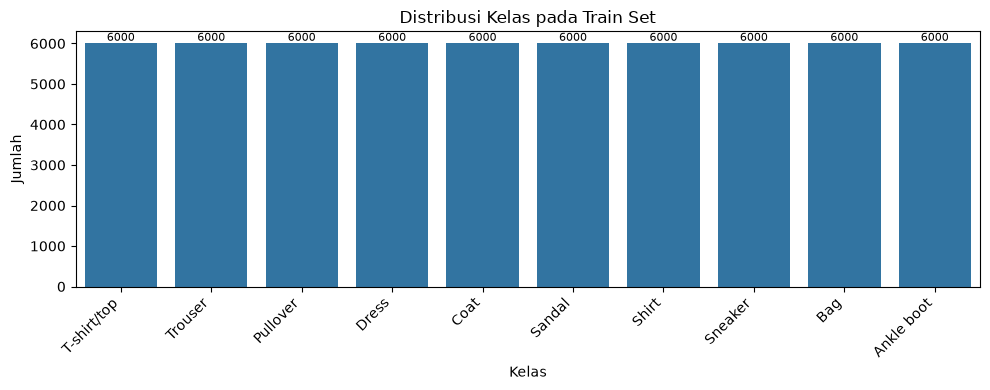

In [28]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.

class_names = {
    0: "T-shirt/top", 1: "Trouser", 2: "Pullover", 3: "Dress", 4: "Coat",
    5: "Sandal", 6: "Shirt", 7: "Sneaker", 8: "Bag", 9: "Ankle boot"
}

plt.figure(figsize=(10, 4))
ax = sns.countplot(x="label", data=train_df, order=range(10))
ax.set_xticklabels([class_names[i] for i in range(10)], rotation=45, ha="right")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()), ha="center", va="bottom", fontsize=8)
plt.title("Distribusi Kelas pada Train Set")
plt.xlabel("Kelas")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()


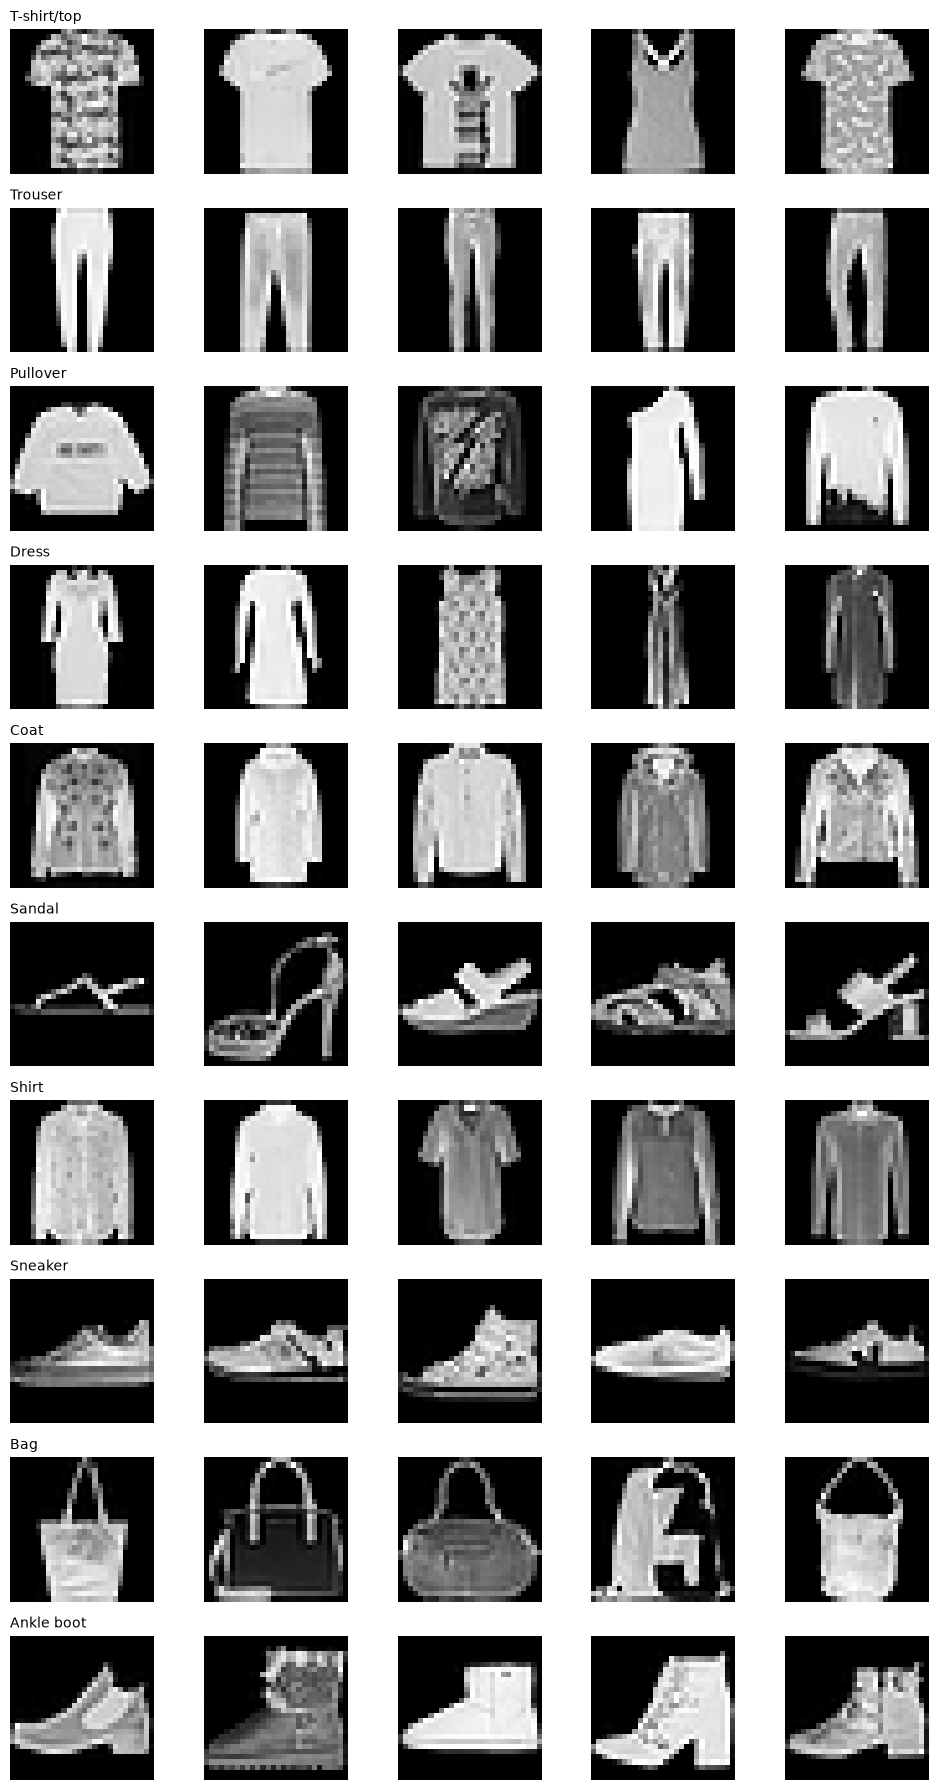

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?

fig, axes = plt.subplots(10, 5, figsize=(10, 18))
for label in range(10):
    idx = train_df[train_df["label"] == label].index[:5]
    for j, i in enumerate(idx):
        img = train_df.iloc[i, 1:].values.reshape(28, 28)
        axes[label, j].imshow(img, cmap="gray")
        axes[label, j].axis("off")
        if j == 0:
            axes[label, j].set_title(class_names[label], loc="left", fontsize=10)
plt.tight_layout()
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

Nilai piksel minimum: 0 | maksimum: 255
Rata-rata nilai piksel: 72.96
Proporsi piksel bernilai 0: 0.5018


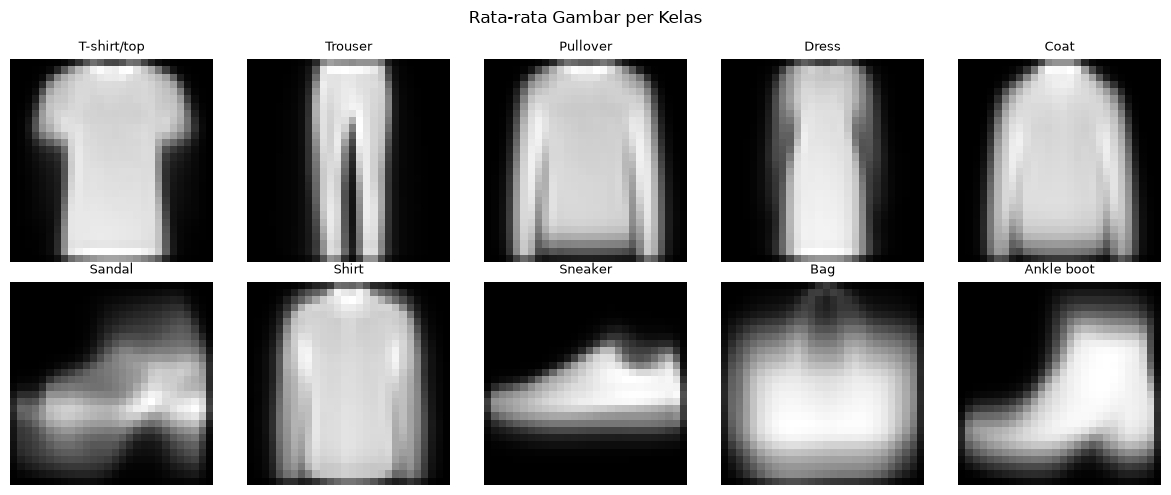

Distribusi kelas test:
label
0    1000
1    1000
2    1000
3    1000
4    1000
5    1000
6    1000
7    1000
8    1000
9    1000
Name: count, dtype: int64


In [5]:
# EDA tambahan: statistik nilai piksel dan rata-rata gambar per kelas.
pixels = train_df.drop(columns=["label"]).values
print("Nilai piksel minimum:", pixels.min(), "| maksimum:", pixels.max())
print("Rata-rata nilai piksel:", pixels.mean().round(2))
print("Proporsi piksel bernilai 0:", (pixels == 0).mean().round(4))

fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for label, ax in enumerate(axes.ravel()):
    mean_img = pixels[train_df["label"].values == label].mean(axis=0).reshape(28, 28)
    ax.imshow(mean_img, cmap="gray")
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")
plt.suptitle("Rata-rata Gambar per Kelas")
plt.tight_layout()
plt.show()

print("Distribusi kelas test:")
print(test_df["label"].value_counts().sort_index())


# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.

y_train_full = train_df["label"].values
X_train_full = train_df.drop(columns=["label"]).values

y_test = test_df["label"].values
X_test = test_df.drop(columns=["label"]).values

print(X_train_full.shape, y_train_full.shape)
print(X_test.shape, y_test.shape)


(60000, 784) (60000,)
(10000, 784) (10000,)


In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).

X_train_full = X_train_full.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

print("Rentang nilai setelah normalisasi:", X_train_full.min(), "-", X_train_full.max())


Rentang nilai setelah normalisasi: 0.0 - 1.0


In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.

X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.10, random_state=42, stratify=y_train_full)

print("Train :", X_train.shape, np.bincount(y_train))
print("Val   :", X_val.shape, np.bincount(y_val))
print("Test  :", X_test.shape, np.bincount(y_test))


Train : (54000, 784) [5400 5400 5400 5400 5400 5400 5400 5400 5400 5400]
Val   : (6000, 784) [600 600 600 600 600 600 600 600 600 600]
Test  : (10000, 784) [1000 1000 1000 1000 1000 1000 1000 1000 1000 1000]


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).

X_train_t = torch.tensor(X_train, dtype=torch.float32).view(-1, 1, 28, 28)
X_val_t = torch.tensor(X_val, dtype=torch.float32).view(-1, 1, 28, 28)
X_test_t = torch.tensor(X_test, dtype=torch.float32).view(-1, 1, 28, 28)

y_train_t = torch.tensor(y_train, dtype=torch.long)
y_val_t = torch.tensor(y_val, dtype=torch.long)
y_test_t = torch.tensor(y_test, dtype=torch.long)

train_loader = DataLoader(TensorDataset(X_train_t, y_train_t), batch_size=64, shuffle=True)
val_loader = DataLoader(TensorDataset(X_val_t, y_val_t), batch_size=64, shuffle=False)
test_loader = DataLoader(TensorDataset(X_test_t, y_test_t), batch_size=64, shuffle=False)

print("Jumlah batch:", len(train_loader), len(val_loader), len(test_loader))


Jumlah batch: 844 94 157


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).

class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)


model_ann = ANN().to(device)
print(model_ann)
print("Jumlah parameter:", sum(p.numel() for p in model_ann.parameters()))


ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.

def train_model(model, train_loader, val_loader, criterion, optimizer, epochs=8):
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            out = model(xb)
            loss = criterion(out, yb)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * xb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            total += xb.size(0)

        train_loss, train_acc = running_loss / total, correct / total

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for xb, yb in val_loader:
                xb, yb = xb.to(device), yb.to(device)
                out = model(xb)
                loss = criterion(out, yb)
                val_loss += loss.item() * xb.size(0)
                val_correct += (out.argmax(dim=1) == yb).sum().item()
                val_total += xb.size(0)

        val_loss, val_acc = val_loss / val_total, val_correct / val_total

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch+1}/{epochs} | train loss {train_loss:.4f} acc {train_acc:.4f} | "
              f"val loss {val_loss:.4f} acc {val_acc:.4f}")

    return history


criterion = nn.CrossEntropyLoss()
optimizer_ann = torch.optim.Adam(model_ann.parameters(), lr=0.001)
history_ann = train_model(model_ann, train_loader, val_loader, criterion, optimizer_ann, epochs=8)


Epoch 1/8 | train loss 0.5435 acc 0.8064 | val loss 0.4469 acc 0.8360
Epoch 2/8 | train loss 0.3837 acc 0.8587 | val loss 0.3680 acc 0.8625
Epoch 3/8 | train loss 0.3407 acc 0.8746 | val loss 0.3592 acc 0.8692
Epoch 4/8 | train loss 0.3179 acc 0.8833 | val loss 0.3268 acc 0.8780
Epoch 5/8 | train loss 0.2963 acc 0.8899 | val loss 0.3354 acc 0.8783
Epoch 6/8 | train loss 0.2794 acc 0.8964 | val loss 0.3252 acc 0.8870
Epoch 7/8 | train loss 0.2670 acc 0.8996 | val loss 0.3102 acc 0.8883
Epoch 8/8 | train loss 0.2545 acc 0.9051 | val loss 0.3120 acc 0.8897


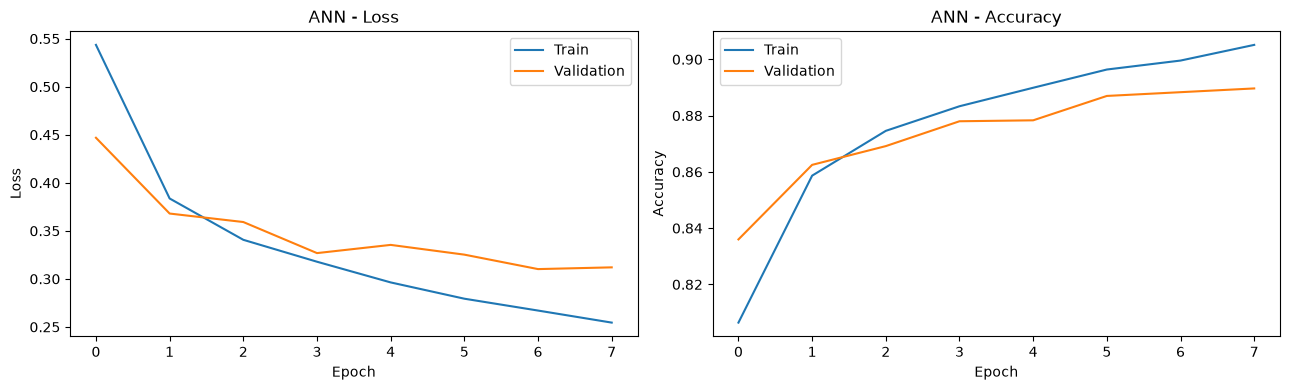

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.

def plot_learning_curve(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(history["train_loss"], label="Train")
    axes[0].plot(history["val_loss"], label="Validation")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history["train_acc"], label="Train")
    axes[1].plot(history["val_acc"], label="Validation")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()
    plt.tight_layout()
    plt.show()


plot_learning_curve(history_ann, "ANN")


In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.

def predict_model(model, loader):
    model.eval()
    preds = []
    with torch.no_grad():
        for xb, _ in loader:
            xb = xb.to(device)
            preds.extend(model(xb).argmax(dim=1).cpu().numpy())
    return np.array(preds)


y_pred_ann = predict_model(model_ann, test_loader)
print("Contoh prediksi:", y_pred_ann[:10])
print("Contoh label asli:", y_test[:10])


Contoh prediksi: [0 1 2 2 3 6 8 2 5 0]
Contoh label asli: [0 1 2 2 3 2 8 6 5 0]


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.

# Perhitungan manual ukuran output:
# Conv1: (28 - 3 + 2*1)/1 + 1 = 28 -> MaxPool2d(2) -> 14
# Conv2: (14 - 3 + 2*1)/1 + 1 = 14 -> MaxPool2d(2) -> 7
# Output akhir: 64 channel x 7 x 7
class SimpleCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model_cnn = SimpleCNN().to(device)
print(model_cnn)
print("Jumlah parameter:", sum(p.numel() for p in model_cnn.parameters()))

dummy = torch.zeros(1, 1, 28, 28).to(device)
print("Bentuk output konvolusi:", model_cnn.features(dummy).shape)


SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Bentuk output konvolusi: torch.Size([1, 64, 7, 7])


Epoch 1/8 | train loss 0.4854 acc 0.8227 | val loss 0.3484 acc 0.8747
Epoch 2/8 | train loss 0.3080 acc 0.8894 | val loss 0.2794 acc 0.8967
Epoch 3/8 | train loss 0.2588 acc 0.9055 | val loss 0.3071 acc 0.8860
Epoch 4/8 | train loss 0.2261 acc 0.9169 | val loss 0.2508 acc 0.9127
Epoch 5/8 | train loss 0.1999 acc 0.9270 | val loss 0.2695 acc 0.8992
Epoch 6/8 | train loss 0.1773 acc 0.9353 | val loss 0.2286 acc 0.9203
Epoch 7/8 | train loss 0.1554 acc 0.9423 | val loss 0.2407 acc 0.9112
Epoch 8/8 | train loss 0.1369 acc 0.9503 | val loss 0.2272 acc 0.9230


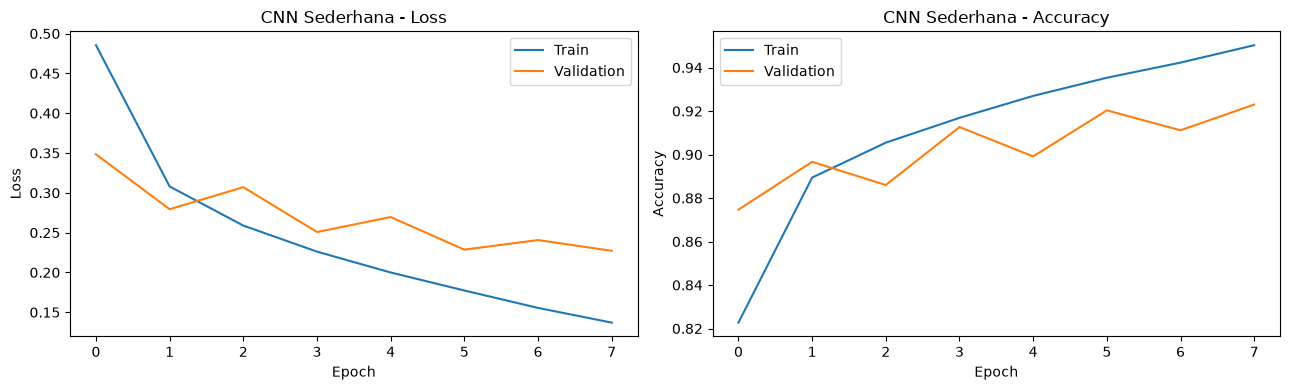

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.

optimizer_cnn = torch.optim.Adam(model_cnn.parameters(), lr=0.001)
history_cnn = train_model(model_cnn, train_loader, val_loader, criterion, optimizer_cnn, epochs=8)
plot_learning_curve(history_cnn, "CNN Sederhana")


In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_cnn = predict_model(model_cnn, test_loader)
print("Contoh prediksi:", y_pred_cnn[:10])
print("Contoh label asli:", y_test[:10])


Contoh prediksi: [0 1 2 6 3 6 8 6 5 0]
Contoh label asli: [0 1 2 2 3 2 8 6 5 0]


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.

class CNNBatchNorm(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model_cnn_bn = CNNBatchNorm().to(device)
print(model_cnn_bn)
print("Jumlah parameter:", sum(p.numel() for p in model_cnn_bn.parameters()))


CNNBatchNorm(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch 1/8 | train loss 0.5196 acc 0.8163 | val loss 0.3227 acc 0.8800
Epoch 2/8 | train loss 0.3620 acc 0.8713 | val loss 0.2723 acc 0.9018
Epoch 3/8 | train loss 0.3197 acc 0.8850 | val loss 0.2580 acc 0.9078
Epoch 4/8 | train loss 0.2888 acc 0.8960 | val loss 0.2438 acc 0.9118
Epoch 5/8 | train loss 0.2688 acc 0.9036 | val loss 0.2707 acc 0.9042
Epoch 6/8 | train loss 0.2492 acc 0.9094 | val loss 0.2352 acc 0.9140
Epoch 7/8 | train loss 0.2325 acc 0.9162 | val loss 0.2307 acc 0.9225
Epoch 8/8 | train loss 0.2210 acc 0.9192 | val loss 0.2312 acc 0.9182


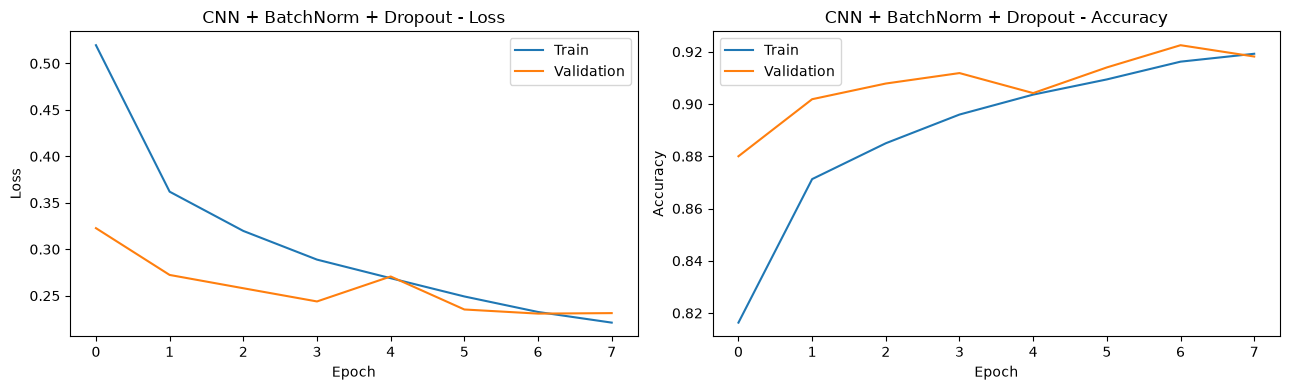

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.

optimizer_cnn_bn = torch.optim.Adam(model_cnn_bn.parameters(), lr=0.001)
history_cnn_bn = train_model(model_cnn_bn, train_loader, val_loader,
                             criterion, optimizer_cnn_bn, epochs=8)
plot_learning_curve(history_cnn_bn, "CNN + BatchNorm + Dropout")


In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.

y_pred_cnn_bn = predict_model(model_cnn_bn, test_loader)
print("Contoh prediksi:", y_pred_cnn_bn[:10])
print("Contoh label asli:", y_test[:10])


Contoh prediksi: [0 1 2 2 3 6 8 6 5 0]
Contoh label asli: [0 1 2 2 3 2 8 6 5 0]


# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.

models = {
    "ANN": (model_ann, y_pred_ann),
    "CNN Sederhana": (model_cnn, y_pred_cnn),
    "CNN + BatchNorm + Dropout": (model_cnn_bn, y_pred_cnn_bn),
}

rows = []
for name, (model, pred) in models.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision (macro)": precision_score(y_test, pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, pred, average="macro", zero_division=0),
        "F1-Score (macro)": f1_score(y_test, pred, average="macro", zero_division=0),
        "Jumlah Parameter": sum(p.numel() for p in model.parameters()),
    })

results_df = pd.DataFrame(rows).set_index("Model").round(4)
results_df


,Accuracy,Precision (macro),Recall (macro),F1-Score (macro),Jumlah Parameter
Model,,,,,
ANN,0.8849,0.8907,0.8849,0.8858,235146
CNN Sederhana,0.9258,0.9271,0.9258,0.9261,421642
CNN + BatchNorm + Dropout,0.9217,0.9226,0.9217,0.9212,421834


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.

best_name = results_df["Accuracy"].idxmax()
best_pred = models[best_name][1]
best_model = models[best_name][0]
print("Model terbaik:", best_name)
print(classification_report(y_test, best_pred, target_names=[class_names[i] for i in range(10)]))


Model terbaik: CNN Sederhana
              precision    recall  f1-score   support

 T-shirt/top       0.88      0.87      0.88      1000
     Trouser       0.99      0.99      0.99      1000
    Pullover       0.92      0.85      0.88      1000
       Dress       0.93      0.95      0.94      1000
        Coat       0.90      0.88      0.89      1000
      Sandal       0.98      0.99      0.98      1000
       Shirt       0.76      0.82      0.79      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.99      0.99      0.99      1000
  Ankle boot       0.98      0.96      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



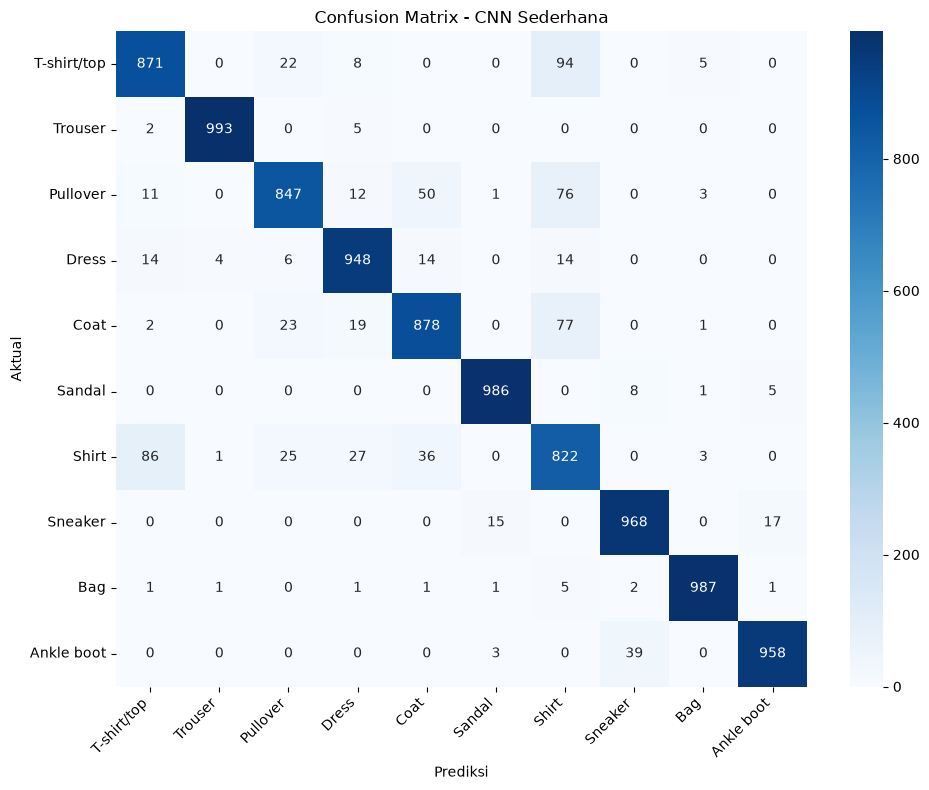

In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?

cm = confusion_matrix(y_test, best_pred)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=[class_names[i] for i in range(10)],
            yticklabels=[class_names[i] for i in range(10)])
plt.title(f"Confusion Matrix - {best_name}")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


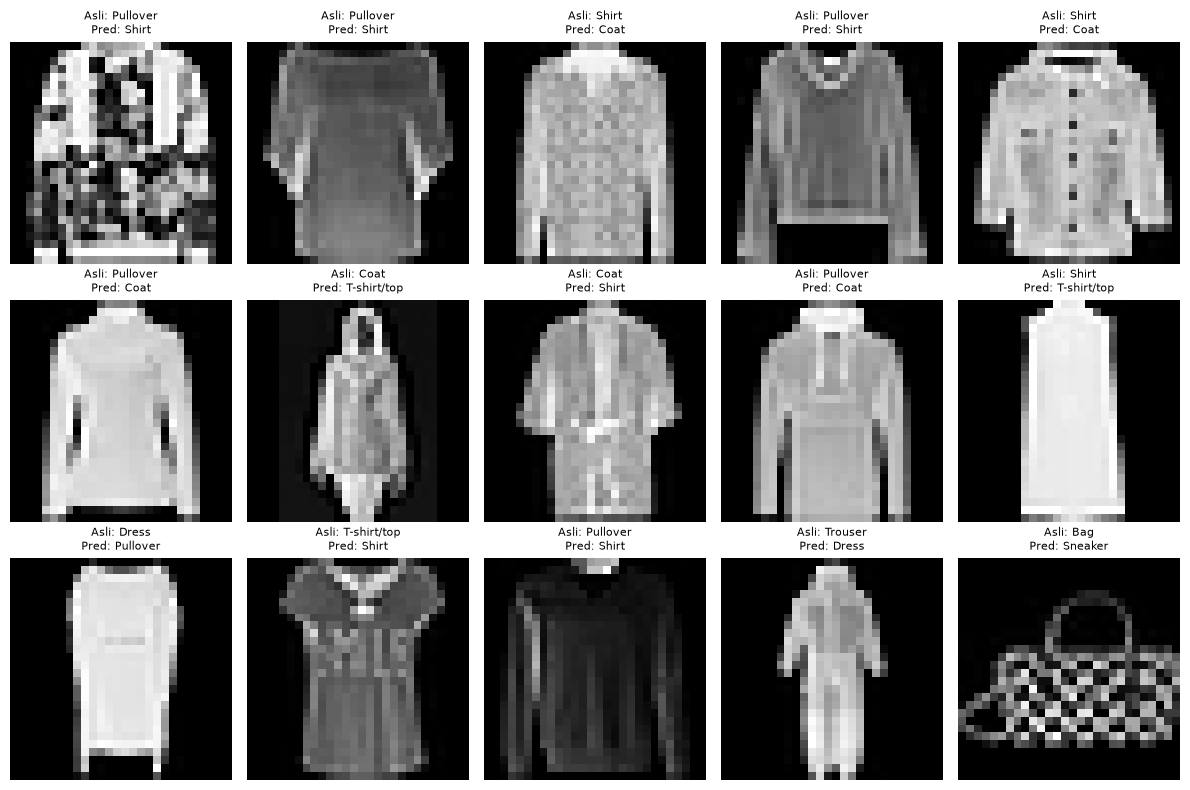

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.

wrong_idx = np.where(best_pred != y_test)[0][:15]
fig, axes = plt.subplots(3, 5, figsize=(12, 8))
for ax, idx in zip(axes.ravel(), wrong_idx):
    img = X_test[idx].reshape(28, 28)
    ax.imshow(img, cmap="gray")
    ax.axis("off")
    ax.set_title(f"Asli: {class_names[y_test[idx]]}\nPred: {class_names[best_pred[idx]]}", fontsize=8)
plt.tight_layout()
plt.show()


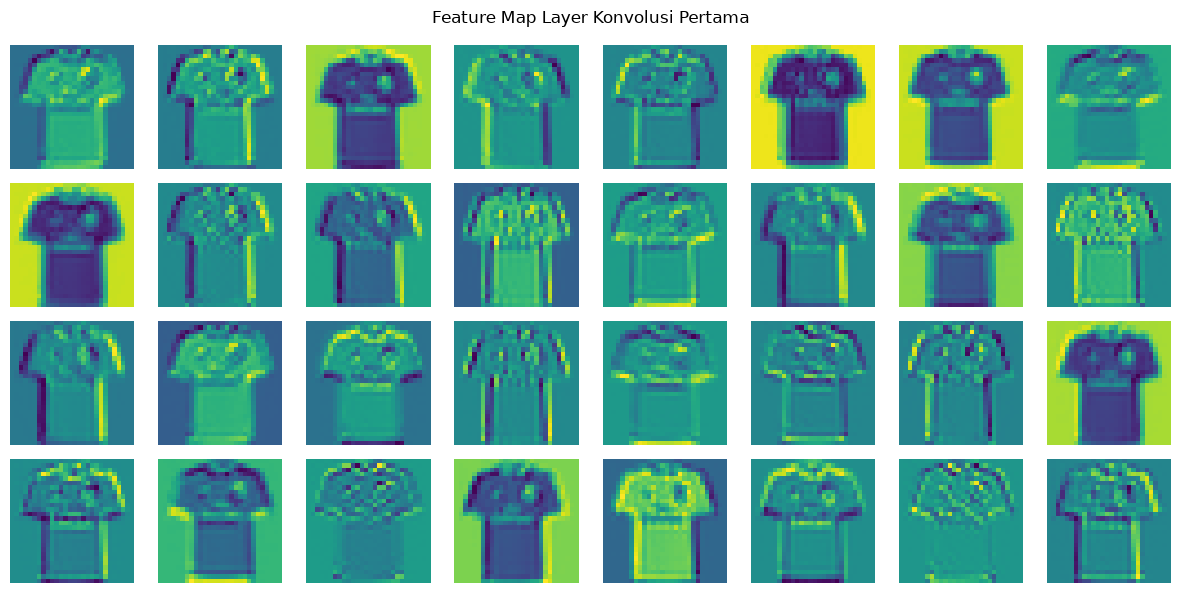

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?

img = X_test_t[0:1].to(device)
best_model.eval()
with torch.no_grad():
    feature_maps = best_model.features[0](img)

feature_maps = feature_maps.detach().cpu().numpy()[0]
fig, axes = plt.subplots(4, 8, figsize=(12, 6))
for i, ax in enumerate(axes.ravel()):
    ax.imshow(feature_maps[i], cmap="viridis")
    ax.axis("off")
plt.suptitle("Feature Map Layer Konvolusi Pertama")
plt.tight_layout()
plt.show()


In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.

torch.save(best_model.state_dict(), "model.pth")
print("Model", best_name, "disimpan sebagai model.pth")
print(best_model)


Model CNN Sederhana disimpan sebagai model.pth
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

Fashion-MNIST memiliki 60.000 data train dan 10.000 data test yang terbagi merata ke 10 kelas (masing-masing 6.000 dan 1.000 gambar). Setiap gambar berukuran 28×28 piksel grayscale dengan nilai 0–255. Sekitar 50,18% piksel bernilai 0 karena latar gambar berwarna hitam, dan rata-rata intensitas piksel adalah 72,96. Dari visualisasi contoh gambar, kelas yang secara visual paling mirip adalah Shirt, T-shirt/top, Pullover, dan Coat, karena semuanya berupa pakaian atasan dengan siluet serupa. Kemiripan ini nantinya tercermin pada confusion matrix.

Berdasarkan evaluasi pada test set, ANN baseline memperoleh Accuracy 0,8849, Precision macro 0,8907, Recall macro 0,8849, dan F1 macro 0,8858 dengan 235.146 parameter. CNN sederhana memberikan hasil terbaik dengan Accuracy 0,9258, Precision macro 0,9271, Recall macro 0,9258, dan F1 macro 0,9261 menggunakan 421.642 parameter. CNN dengan Batch Normalization dan Dropout memperoleh Accuracy 0,9217, Precision macro 0,9226, Recall macro 0,9217, dan F1 macro 0,9212 dengan 421.834 parameter. Jadi CNN sederhana unggul tipis sekitar 0,4 poin persentase atas CNN dengan BatchNorm + Dropout, dan sekitar 4,1 poin persentase atas ANN.

Perbedaan performa ini berkaitan erat dengan cara model memproses gambar. ANN melakukan Flatten sehingga seluruh hubungan spasial antar piksel hilang dan setiap piksel diperlakukan sebagai fitur independen; akibatnya ANN membutuhkan lebih banyak parameter untuk mempelajari pola dan tetap kalah akurat. CNN mempertahankan struktur spasial melalui operasi konvolusi dan pooling, sehingga mampu menangkap pola lokal seperti tepi, garis, dan tekstur dengan jumlah parameter yang efisien. Meskipun CNN memiliki parameter lebih banyak (421.642 vs 235.146), tambahan parameter tersebut dipakai untuk filter konvolusi yang berbagi bobot (weight sharing), sehingga representasinya jauh lebih efektif untuk gambar. Batch Normalization dan Dropout menambah 192 parameter, relatif sangat kecil dibanding total parameter.

Dari learning curve, ANN menunjukkan train accuracy 0,9051 dan validation 0,8897 pada epoch ke-8 dengan train loss 0,2545 dan validation loss 0,3120, sehingga sudah mulai terlihat jarak (gap) yang menandakan overfitting ringan. CNN sederhana menunjukkan train accuracy 0,9503 dan validation 0,9230 dengan train loss 0,1369 dan validation loss 0,2272; gap-nya lebih besar, artinya CNN sederhana paling cepat menghafal data train. CNN dengan BatchNorm + Dropout menunjukkan train accuracy 0,9192 dan validation 0,9182 dengan train loss 0,2210 dan validation loss 0,2312, hampir tidak ada gap. Dengan demikian Batch Normalization dan Dropout berhasil menekan overfitting dan membuat kurva train–validation lebih rapat, tetapi pada 8 epoch hasil akhirnya sedikit lebih rendah dari CNN sederhana; regularization yang kuat membuat model belajar lebih lambat sehingga mungkin membutuhkan epoch atau learning rate yang berbeda untuk mencapai performa puncaknya.

Classification report model terbaik (CNN sederhana) memperlihatkan bahwa kelas Shirt paling sulit dikenali dengan F1 0,79 (precision 0,76, recall 0,82), diikuti Pullover (F1 0,88), T-shirt/top (F1 0,88), dan Coat (F1 0,89). Sebaliknya, Trouser, Bag, Sandal, Ankle boot, dan Sneaker hampir sempurna (F1 0,96–0,99). Confusion matrix mengonfirmasi bahwa kesalahan terbanyak terjadi antar-kelas pakaian atasan, terutama Shirt yang sering diprediksi sebagai T-shirt/top, Pullover, atau Coat, sesuai kemiripan visual yang terlihat pada EDA. Feature map dari layer konvolusi pertama menunjukkan bahwa filter-filter awal menangkap pola dasar seperti tepi vertikal/horizontal, garis kontur, dan area transisi terang–gelap; beberapa filter merespons tepi objek, filter lain merespons tekstur kain, dan sebagian menghasilkan peta aktivasi yang hampir kosong untuk area latar.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

## Kesimpulan dan Saran

Eksperimen menunjukkan bahwa CNN lebih tepat digunakan untuk klasifikasi gambar dibanding ANN. CNN sederhana mencapai Accuracy 0,9258 dan F1 macro 0,9261, mengungguli ANN baseline (Accuracy 0,8849; F1 macro 0,8858) dengan selisih sekitar 4 poin persentase. Keunggulan ini berasal dari kemampuan konvolusi mempertahankan informasi spasial dan menangkap pola lokal, bukan sekadar dari jumlah parameter. Penambahan Batch Normalization dan Dropout menghasilkan kurva belajar yang paling stabil dengan gap train–validation terkecil (0,9192 vs 0,9182), meskipun pada pengaturan 8 epoch accuracy-nya (0,9217) sedikit di bawah CNN sederhana. Kelas Shirt, Pullover, T-shirt/top, dan Coat merupakan kelas yang paling sering tertukar karena bentuk visualnya mirip.

Saran untuk pengembangan selanjutnya adalah 
- latih CNN dengan BatchNorm + Dropout lebih lama atau lakukan tuning learning rate/ukuran batch agar regularisasinya benar-benar terlihat manfaatnya
- gunakan data augmentation ringan seperti geser gambar beberapa piksel atau flip horizontal untuk mengurangi overfitting pada CNN sederhana
- coba arsitektur yang lebih modern atau tambahkan layer konvolusi ketiga
- lakukan hyperparameter tuning pada jumlah filter, dropout rate, dan optimizer
- pertimbangkan class-balanced loss atau fokus khusus pada kelas Shirt yang paling sering salah klasifikasi. Model terbaik sudah disimpan sebagai `model.pth` dan definisi class-nya (`SimpleCNN`) dapat digunakan kembali pada tugas Deployment.